In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
def f(x):
    return 3*x**2 -4*x+5

In [3]:
f(3.0)


20.0

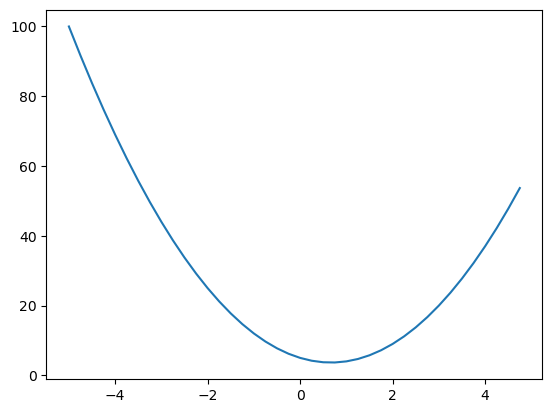

In [4]:
xs=np.arange(-5,5,0.25)
ys=f(xs)
plt.plot(xs,ys)

In [5]:
h=0.00000001
x=2/3
(f(x+h)-f(x))/h

0.0

In [6]:
a=2
b=-3.0
c=10
d=a*b+c
print(d)

4.0


In [7]:
h=0.0001

a=2
b=-3.0
c=10

d1=a*b+c

c+=h
d2=a*b+c
print("d1:",d1)
print("d2:",d2)

print("slope",(d2-d1)/h)

d1: 4.0
d2: 4.0001
slope 0.9999999999976694


In [8]:
class Value:
    def __init__(self, data,_children=(),_op="", label="" ):
        self.data = data
        self.grad=0.0
        self._backward= lambda : None
        self._prev=set(_children)
        self._op=_op
        self.label=label
    def __repr__(self):
        return f"Value(data={self.data})"
        
    def __add__(self,other):
        out=Value(self.data + other.data,(self, other),"+")                
        def _backward():
            self.grad=1.0*out.grad
            other.grad=1.0*out.grad          
        out._backward=_backward
        return out
        
    def __mul__(self,other):
        out=Value(self.data * other.data,(self, other),"*")
        
        def _backward():
            self.grad=other.data*out.grad
            other.grad=self.data*out.grad
        out._backward=_backward
        
        return out
        
    def tanh(self):
        x=self.data
        t=(math.exp(2*x)-1)/(math.exp(2*x)+1)
        out=Value(t,(self,),"tanh")
        def _backward():
            self.grad=(1-t**2)*out.grad
        out._backward=_backward
        return out

        
a=Value(2.0,label="a")
b=Value(-3.0,label="b")
c=Value(10.0,label="c")
##a*b+c
#(a.__mul__(b)).__add__(c)
e=a*b; e.label="e"
d=e+c;d.label="d"
f=Value(-2.0,label="f")
L=d*f;L.label="L"
L

Value(data=-8.0)

In [9]:
d._prev

{Value(data=-6.0), Value(data=10.0)}

In [10]:
d._op

'+'

In [11]:
!pip install graphviz

In [12]:
!conda install -c conda-forge graphviz python-graphviz -y

^C
Jupyter detected...
3 channel Terms of Service accepted
Retrieving notices: done
Channels:
 - conda-forge
 - defaults
Platform: win-64
Solving environment: done

## Package Plan ##

  environment location: C:\Users\aidyn\anaconda3

  added / updated specs:
    - graphviz
    - python-graphviz


The following packages will be downloaded:

    package                    |            build
    ---------------------------|-----------------
    openssl-3.6.5              |       hf411b9b_0         9.0 MB  conda-forge
    ------------------------------------------------------------
                                           Total:         9.0 MB

The following packages will be UPDATED:

  openssl                                  3.6.4-hf411b9b_0 --> 3.6.5-hf411b9b_0 



openssl-3.6.5        | 9.0 MB    |            |   0% 
openssl-3.6.5        | 9.0 MB    |            |   0% 
openssl-3.6.5        | 9.0 MB    | 2          |   2% 
openssl-3.6.5        | 9.0 MB    | 6          |   6% 
openss



==> WARNING: A newer version of conda exists. <==
    current version: 26.1.1
    latest version: 26.9.2

Please update conda by running

    $ conda update -n base -c conda-forge conda



# >>>>>>>>>>>>>>>>>>>>>> ERROR REPORT <<<<<<<<<<<<<<<<<<<<<<

    Traceback (most recent call last):
      File "C:\Users\aidyn\anaconda3\Lib\site-packages\conda\gateways\disk\delete.py", line 144, in unlink_or_rename_to_trash
        os.unlink(path)
        ~~~~~~~~~^^^^^^
    PermissionError: [WinError 5] Отказано в доступе: 'C:\\Users\\aidyn\\anaconda3\\Library\\bin\\libcrypto-3-x64.dll.c~'
    
    During handling of the above exception, another exception occurred:
    
    Traceback (most recent call last):
      File "C:\Users\aidyn\anaconda3\Lib\site-packages\conda\gateways\disk\delete.py", line 147, in unlink_or_rename_to_trash
        os.rename(path, path + ".conda_trash")
        ~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    FileExistsError: [WinError 183] Невозможно создать файл, так как он

In [2]:
from graphviz import Digraph

def trace(root):
    # builds a set of all nodes and edges in a graph
    nodes, edges = set(), set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)
    build(root)
    return nodes, edges

def draw_dot(root):
    dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'}) # LR = left to right
    
    nodes, edges = trace(root)
    for n in nodes:
        uid = str(id(n))
        # for any value in the graph, create a rectangular ('record') node for it
        dot.node(name = uid, label = "{%s | data %.4f | grad %.4f}" % (n.label,n.data, n.grad ), shape='record')
        if n._op:
            # if this value is a result of some operation, create an op node for it
            dot.node(name = uid + n._op, label = n._op)
            # and connect this node to it
            dot.edge(uid + n._op, uid)
            
    for n1, n2 in edges:
        # connect n1 to the op node of n2
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)
        
    return dot


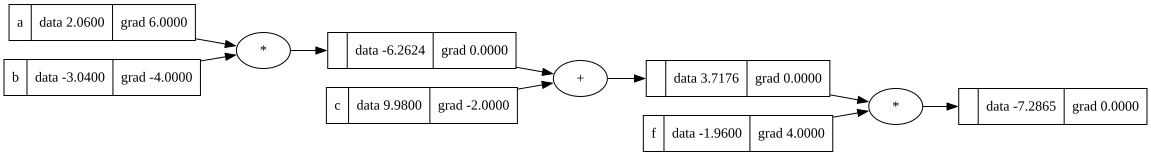

In [31]:
draw_dot(L)

In [32]:
def lol():
    h=0.0001
    a=Value(2.0,label="a")
    b=Value(-3.0,label="b")
    c=Value(10.0,label="c")
    e=a*b; e.label="e"
    d=e+c;d.label="d"
    f=Value(-2.0,label="f")
    L=d*f;L.label="L"
    L1=L.data


    a=Value(2.0,label="a")
    b=Value(-3.0,label="b")
    c=Value(10.0,label="c")
    e=a*b; e.label="e"
    d=e+c;d.label="d"
    f=Value(-2.0,label="f")
    L=d*f;L.label="L"
    L2=L.data+h

    print((L2-L1)/h)
lol()

0.9999999999976694


In [33]:
L.grad=1

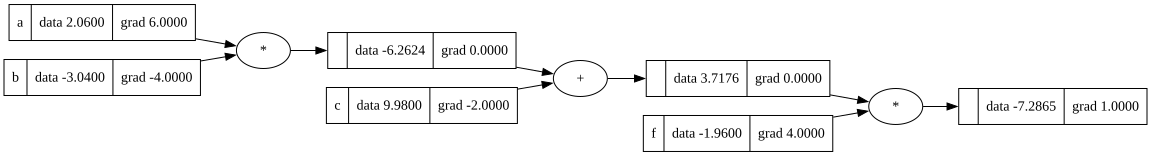

In [34]:
draw_dot(L)

In [35]:
f.grad=4
d.grad=-2

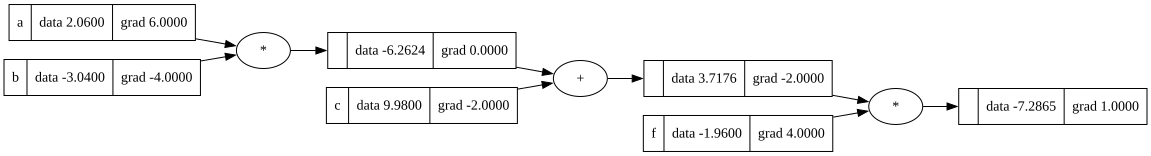

In [36]:
draw_dot(L)

In [37]:
c.grad=-2
e.grad=-2

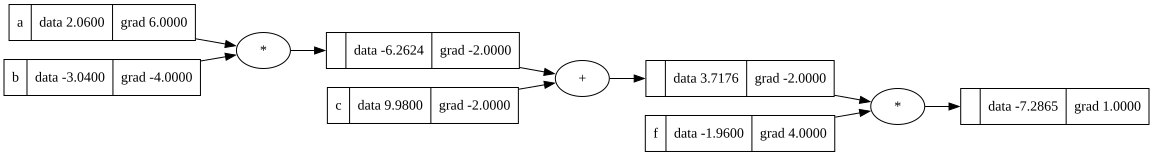

In [38]:
draw_dot(L)

In [39]:
a.grad=-2*(-3)
b.grad=-2*2

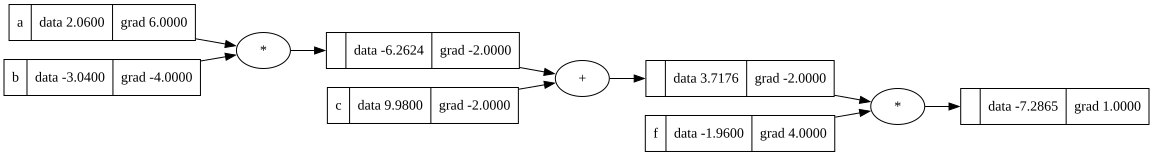

In [40]:
draw_dot(L)

In [41]:
a.data+=0.01*a.grad
b.data+=0.01*b.grad
c.data+=0.01*c.grad
f.data+=0.01*f.grad

e=a*b
d=e+c
L=d*f
print(L.data)

-46.97032704860435


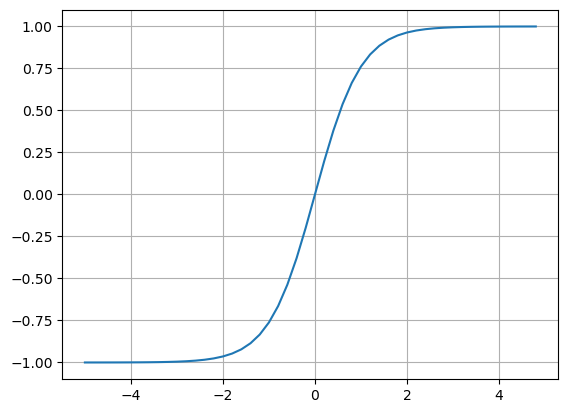

In [42]:
plt.plot(np.arange(-5,5,0.2), np.tanh(np.arange(-5,5,0.2))); plt.grid();

In [43]:
## inputs x1,x2
x1=Value(2,label="x1")
x2=Value(0,label="x2")

## weights w1, w2
w1=Value(-3,label="w1")
w2=Value(1,label="w2")

## bias of the neuron
b=Value(6.8813735870195432, label="b")

##x1*w1 + x2*w2 + b
x1w1=x1*w1; x1w1.label="x1*w1"
x2w2=x2*w2; x2w2.label="x2*w2"
x1w1x2w2=x1w1+x2w2; x1w1x2w2.label="x1w1+x2w2"
n=x1w1x2w2+b;n.label="n"
o=n.tanh();o.label="o"


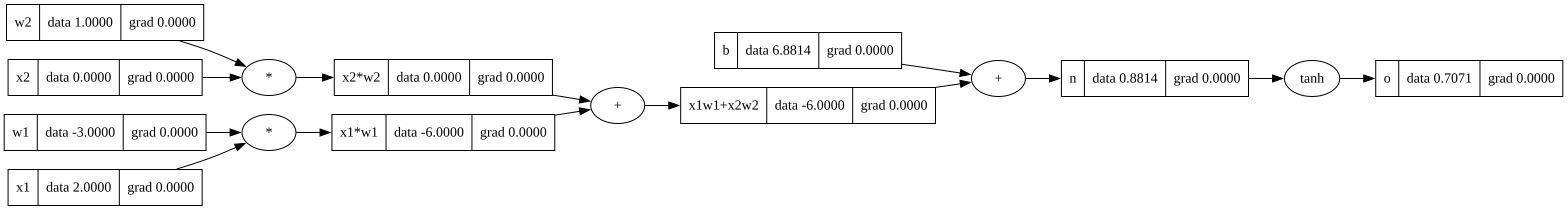

In [44]:
draw_dot(o)

In [45]:
o.grad=1.0

In [ ]:
## o=tanh
## do/dn=1 -tanh**2 = 1 - o**2 


In [46]:
1-o.data**2

0.4999999999999999

In [47]:
n.grad=0.5

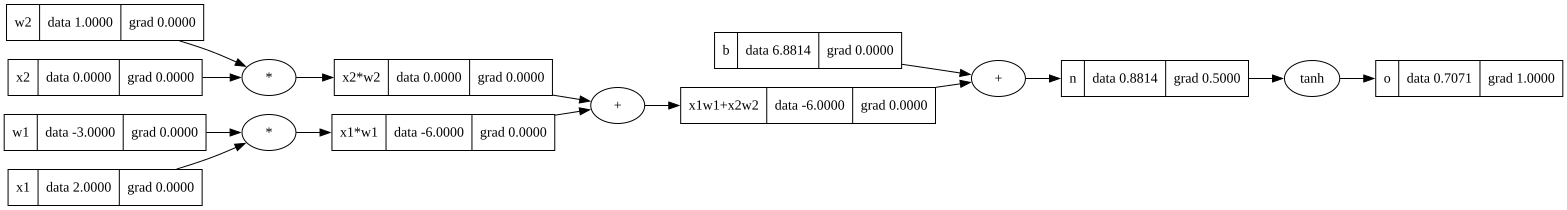

In [48]:
draw_dot(o)

In [49]:
x1w1x2w2.grad=0.5
b.grad=0.5

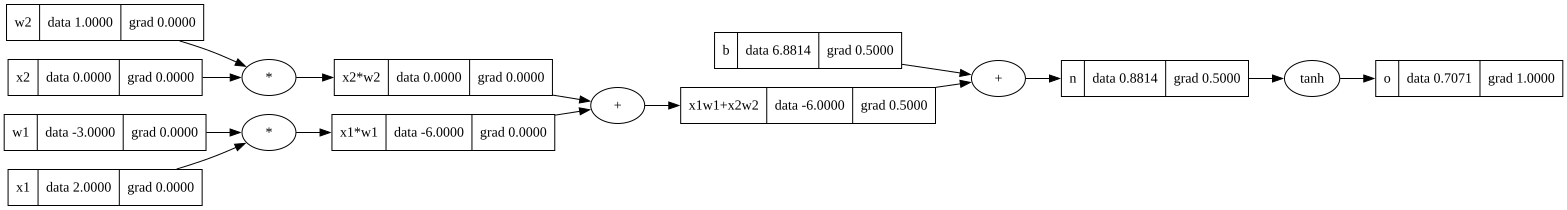

In [50]:
draw_dot(o)

In [51]:
x1w1.grad=0.5
x2w2.grad=0.5

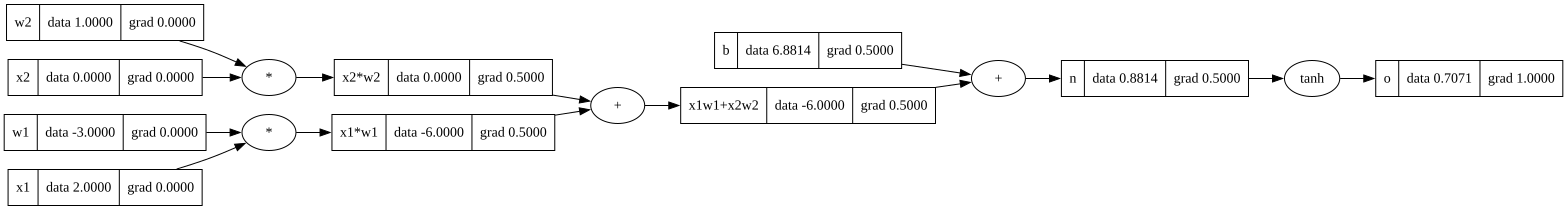

In [52]:
draw_dot(o)

In [53]:
x2.grad=w2.data*x2w2.grad
w2.grad=x2.data*x2w2.grad

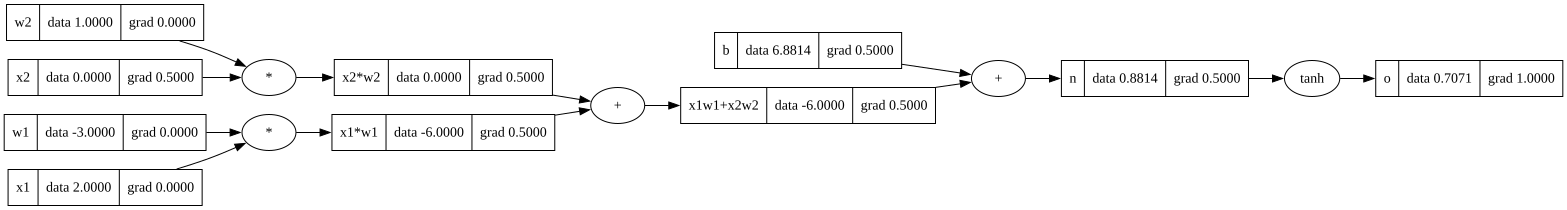

In [54]:
draw_dot(o)

In [55]:
x1.grad=w1.data*x1w1.grad
w1.grad=x1.data*x1w1.grad

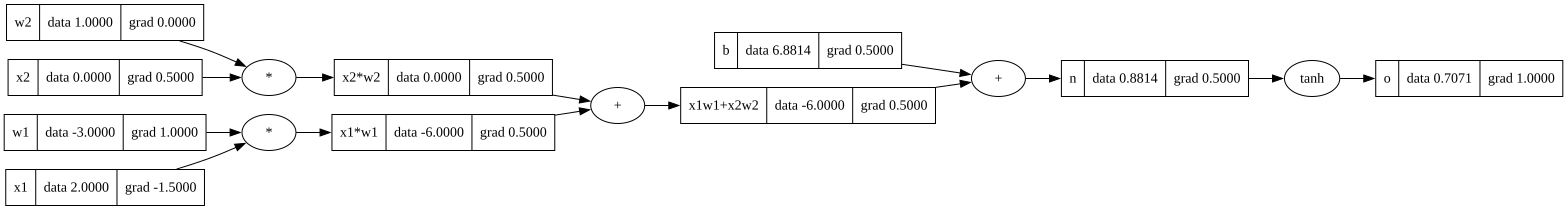

In [56]:
draw_dot(o)

In [57]:
## inputs x1,x2
x1=Value(2,label="x1")
x2=Value(0,label="x2")

## weights w1, w2
w1=Value(-3,label="w1")
w2=Value(1,label="w2")

## bias of the neuron
b=Value(6.8813735870195432, label="b")

##x1*w1 + x2*w2 + b
x1w1=x1*w1; x1w1.label="x1*w1"
x2w2=x2*w2; x2w2.label="x2*w2"
x1w1x2w2=x1w1+x2w2; x1w1x2w2.label="x1w1+x2w2"
n=x1w1x2w2+b;n.label="n"
o=n.tanh();o.label="o"


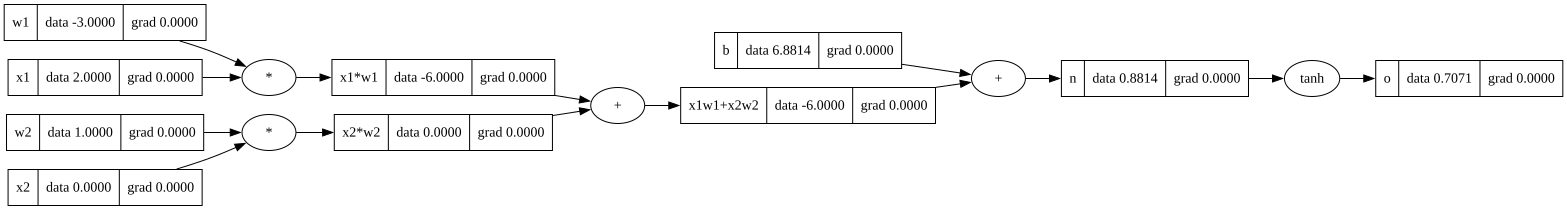

In [58]:
## variable are redifined and now grads should be zero
draw_dot(o)

In [59]:
o.grad=1.0
## now the grad value for o is 1


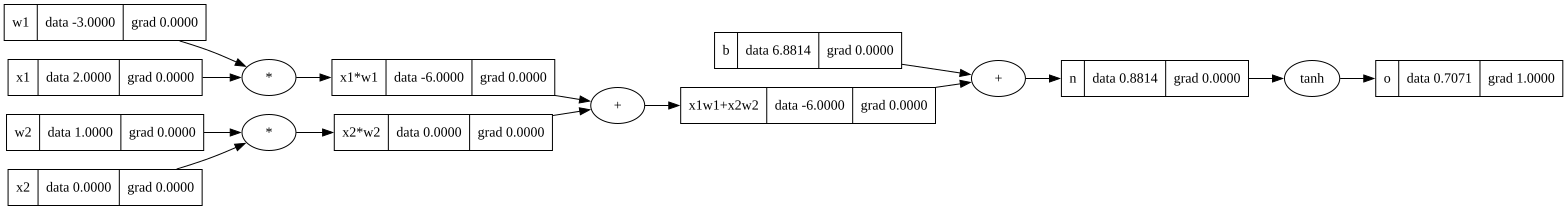

In [60]:
draw_dot(o)

In [61]:
o._backward()
## now grad n should be 0.5

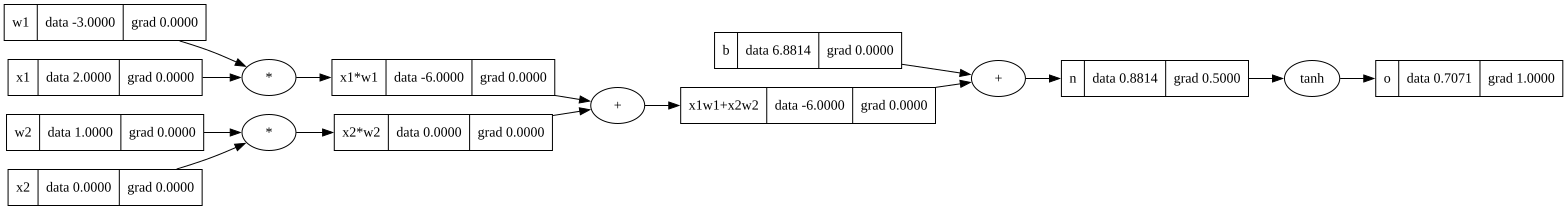

In [62]:
draw_dot(o)

In [63]:
n._backward()
## ## now grad b and x1w1+x2w2 should be 0.5

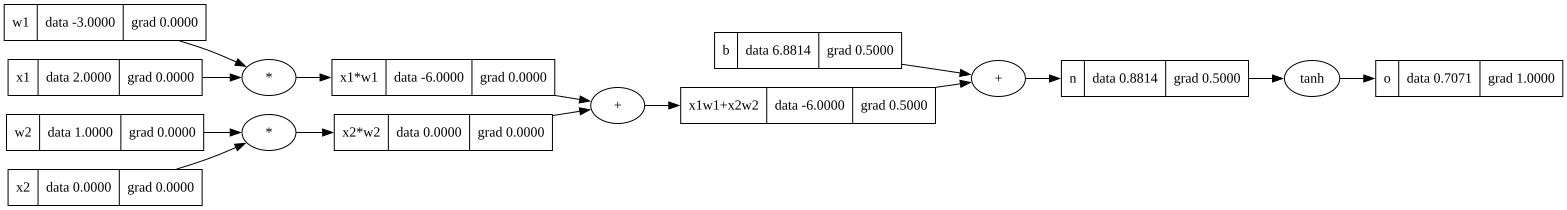

In [64]:
draw_dot(o)

In [65]:
b._backward()
x1w1x2w2._backward()

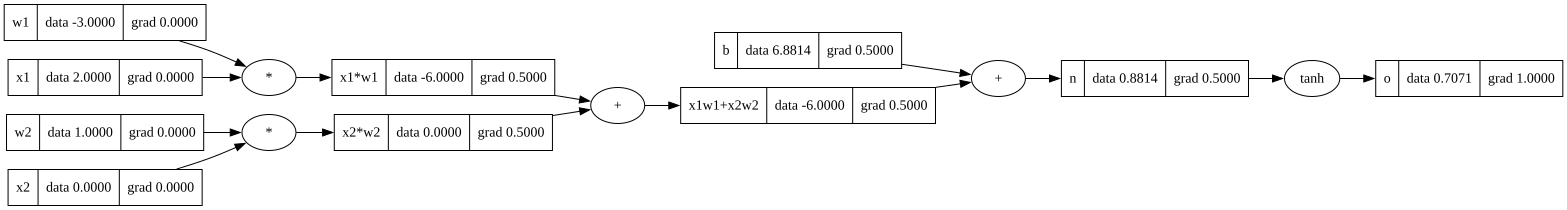

In [66]:
draw_dot(o)

In [67]:
x1w1._backward()
x2w2._backward()

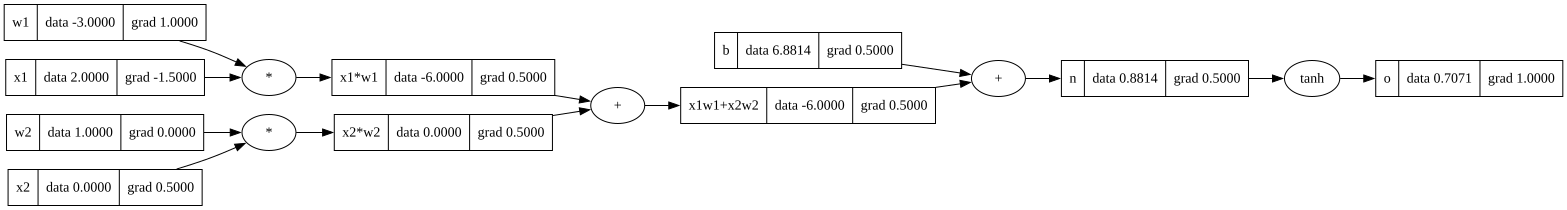

In [68]:
draw_dot(o)

In [69]:
topo = []
visited = set()

def build_topo(v):
    if v not in visited:
        visited.add(v)
        for child in v._prev:
            build_topo(child)
        topo.append(v)

build_topo(o)
topo

[Value(data=-3),
 Value(data=2),
 Value(data=-6),
 Value(data=1),
 Value(data=0),
 Value(data=0),
 Value(data=-6),
 Value(data=6.881373587019543),
 Value(data=0.8813735870195432),
 Value(data=0.7071067811865476)]

In [70]:
## inputs x1,x2
x1=Value(2,label="x1")
x2=Value(0,label="x2")

## weights w1, w2
w1=Value(-3,label="w1")
w2=Value(1,label="w2")

## bias of the neuron
b=Value(6.8813735870195432, label="b")

##x1*w1 + x2*w2 + b
x1w1=x1*w1; x1w1.label="x1*w1"
x2w2=x2*w2; x2w2.label="x2*w2"
x1w1x2w2=x1w1+x2w2; x1w1x2w2.label="x1w1+x2w2"
n=x1w1x2w2+b;n.label="n"
o=n.tanh();o.label="o"

In [71]:
o.grad=1.0

In [72]:
topo = []
visited = set()

def build_topo(v):
    if v not in visited:
        visited.add(v)
        for child in v._prev:
            build_topo(child)
        topo.append(v)

build_topo(o)

for node in reversed(topo):
    node._backward()

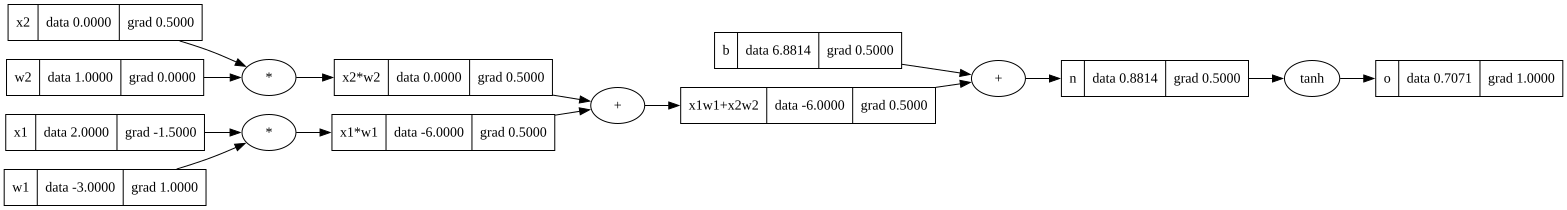

In [73]:
draw_dot(o)

In [74]:
## added backward to class value
class Value:
    def __init__(self, data,_children=(),_op="", label="" ):
        self.data = data
        self.grad=0.0
        self._backward= lambda : None
        self._prev=set(_children)
        self._op=_op
        self.label=label
    def __repr__(self):
        return f"Value(data={self.data})"
        
    def __add__(self,other):
        out=Value(self.data + other.data,(self, other),"+")                
        def _backward():
            self.grad=1.0*out.grad
            other.grad=1.0*out.grad          
        out._backward=_backward
        return out
        
    def __mul__(self,other):
        out=Value(self.data * other.data,(self, other),"*")
        
        def _backward():
            self.grad=other.data*out.grad
            other.grad=self.data*out.grad
        out._backward=_backward
        
        return out
        
    def tanh(self):
        x=self.data
        t=(math.exp(2*x)-1)/(math.exp(2*x)+1)
        out=Value(t,(self,),"tanh")
        def _backward():
            self.grad=(1-t**2)*out.grad
        out._backward=_backward
        return out
    def backward(self): ## added function backward to class
        topo = []
        visited = set()
        
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)
        
        build_topo(self)
        self.grad=1
        for node in reversed(topo):
            node._backward()
                    
a=Value(2.0,label="a")
b=Value(-3.0,label="b")
c=Value(10.0,label="c")
##a*b+c
#(a.__mul__(b)).__add__(c)
e=a*b; e.label="e"
d=e+c;d.label="d"
f=Value(-2.0,label="f")
L=d*f;L.label="L"
L

Value(data=-8.0)

In [75]:
## inputs x1,x2
x1=Value(2,label="x1")
x2=Value(0,label="x2")

## weights w1, w2
w1=Value(-3,label="w1")
w2=Value(1,label="w2")

## bias of the neuron
b=Value(6.8813735870195432, label="b")

##x1*w1 + x2*w2 + b
x1w1=x1*w1; x1w1.label="x1*w1"
x2w2=x2*w2; x2w2.label="x2*w2"
x1w1x2w2=x1w1+x2w2; x1w1x2w2.label="x1w1+x2w2"
n=x1w1x2w2+b;n.label="n"
o=n.tanh();o.label="o"

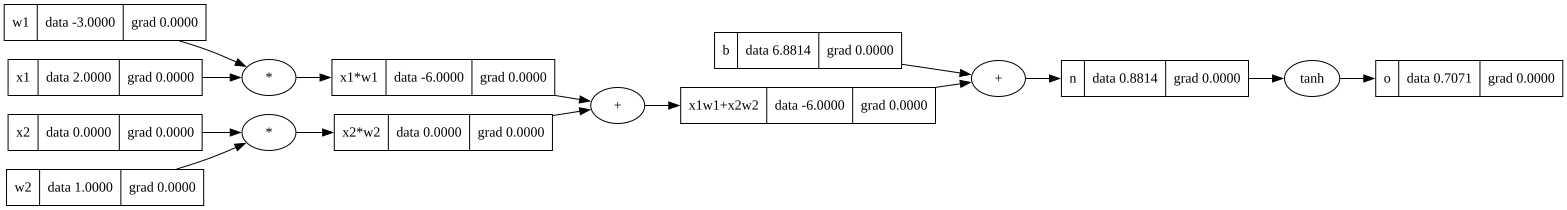

In [76]:
## after adding backward function to class value and initianlize netowork grads every where are zero
draw_dot(o)

In [77]:
## backward
o.backward()

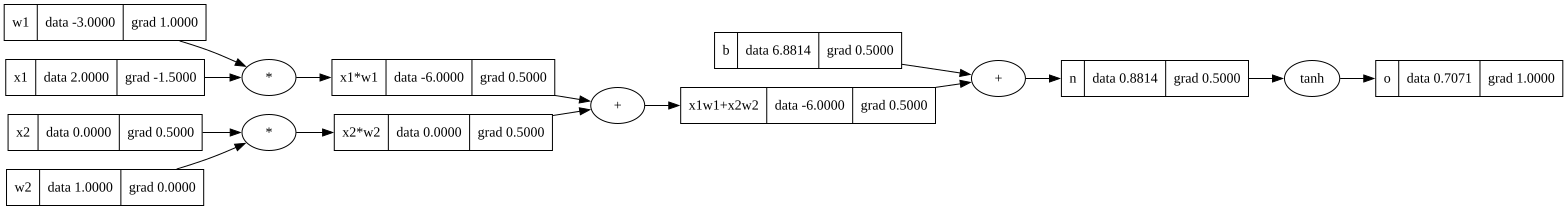

In [78]:
draw_dot(o)

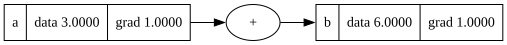

In [79]:
### bag in the backward function
a=Value(3,label="a")
b=a+a;b.label="b"
b.backward()
draw_dot(b)
### grad a should be 2, but results shows 1 (1 is wrong)
### this happens when variable is used more then once in connection to next layer

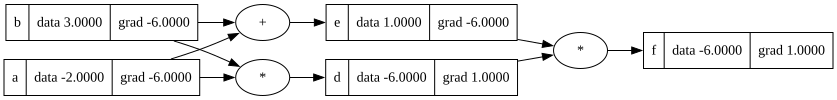

In [80]:
a=Value(-2,label='a')
b=Value(3,label='b')
d=a*b; d.label='d'
e=a+b;e.label='e'
f=d*e;f.label='f'
f.backward()
draw_dot(f)

In [ ]:
# upper result show that df/da=3
# let's calculate
df/da = df/de * de/da + df/dd*dd/da
df/df=1
df/dd=1
df/de=-6
de/da=1
dd/da=3
df/da=(-6) *1 + 1 *  3 = -6 +3=-3
## so result of backward function is not correct
### solution is to accumulate gradients
### instead of "self.grad=1.0*out.grad"should be self.grad+=1.0*out.grad (not "=", should be "+=")

In [81]:
## added backward to class value
## added accumulation function
class Value:
    def __init__(self, data,_children=(),_op="", label="" ):
        self.data = data
        self.grad=0.0
        self._backward= lambda : None
        self._prev=set(_children)
        self._op=_op
        self.label=label
    def __repr__(self):
        return f"Value(data={self.data})"
        
    def __add__(self,other):
        out=Value(self.data + other.data,(self, other),"+")                
        def _backward():
            self.grad+=1.0*out.grad
            other.grad+=1.0*out.grad          
        out._backward=_backward
        return out
        
    def __mul__(self,other):
        out=Value(self.data * other.data,(self, other),"*")
        
        def _backward():
            self.grad+=other.data*out.grad
            other.grad+=self.data*out.grad
        out._backward=_backward
        
        return out
        
    def tanh(self):
        x=self.data
        t=(math.exp(2*x)-1)/(math.exp(2*x)+1)
        out=Value(t,(self,),"tanh")
        def _backward():
            self.grad+=(1-t**2)*out.grad
        out._backward=_backward
        return out
    def backward(self): ## added function backward to class
        topo = []
        visited = set()
        
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)
        
        build_topo(self)
        self.grad=1
        for node in reversed(topo):
            node._backward()
                    
a=Value(2.0,label="a")
b=Value(-3.0,label="b")
c=Value(10.0,label="c")
##a*b+c
#(a.__mul__(b)).__add__(c)
e=a*b; e.label="e"
d=e+c;d.label="d"
f=Value(-2.0,label="f")
L=d*f;L.label="L"
L

Value(data=-8.0)

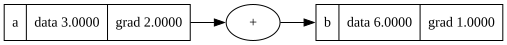

In [82]:
### now let's check the example with 2 a's
a=Value(3,label="a")
b=a+a;b.label="b"
b.backward()
draw_dot(b)
# grad for this case is correct

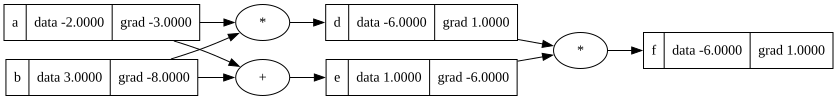

In [83]:
## now check the following example a.grad should = -3
a=Value(-2,label='a')
b=Value(3,label='b')
d=a*b; d.label='d'
e=a+b;e.label='e'
f=d*e;f.label='f'
f.backward()
draw_dot(f)

*Now let focus on value class*

In [84]:
class Value:
    def __init__(self, data,_children=(),_op="", label="" ):
        self.data = data
        self.grad=0.0
        self._backward= lambda : None
        self._prev=set(_children)
        self._op=_op
        self.label=label
    def __repr__(self):
        return f"Value(data={self.data})"
        
    def __add__(self,other):
        out=Value(self.data + other.data,(self, other),"+")                
        def _backward():
            self.grad+=1.0*out.grad
            other.grad+=1.0*out.grad          
        out._backward=_backward
        return out
        
    def __mul__(self,other):
        out=Value(self.data * other.data,(self, other),"*")
        
        def _backward():
            self.grad+=other.data*out.grad
            other.grad+=self.data*out.grad
        out._backward=_backward
        
        return out
        
    def tanh(self):
        x=self.data
        t=(math.exp(2*x)-1)/(math.exp(2*x)+1)
        out=Value(t,(self,),"tanh")
        def _backward():
            self.grad+=(1-t**2)*out.grad
        out._backward=_backward
        return out
    def backward(self): ## added function backward to class
        topo = []
        visited = set()
        
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)
        
        build_topo(self)
        self.grad=1
        for node in reversed(topo):
            node._backward()

In [85]:
## use the following example
## inputs x1,x2
x1=Value(2,label="x1")
x2=Value(0,label="x2")

## weights w1, w2
w1=Value(-3,label="w1")
w2=Value(1,label="w2")

## bias of the neuron
b=Value(6.8813735870195432, label="b")

##x1*w1 + x2*w2 + b
x1w1=x1*w1; x1w1.label="x1*w1"
x2w2=x2*w2; x2w2.label="x2*w2"
x1w1x2w2=x1w1+x2w2; x1w1x2w2.label="x1w1+x2w2"
n=x1w1x2w2+b;n.label="n"
o=n.tanh();o.label="o"

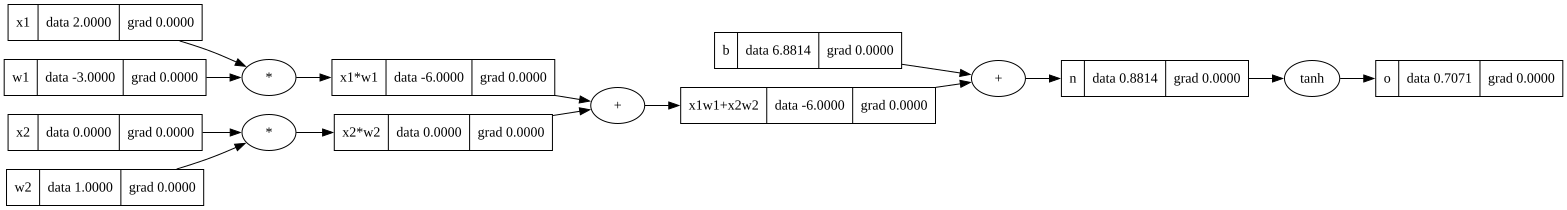

In [86]:
draw_dot(o)

In [87]:
# the next code should produce an error because 1 is not "Value object"
a=Value(2)
a+1

AttributeError: 'int' object has no attribute 'data'

In [ ]:
other= 

In [88]:
# added to "__add__" function
class Value:
    def __init__(self, data,_children=(),_op="", label="" ):
        self.data = data
        self.grad=0.0
        self._backward= lambda : None
        self._prev=set(_children)
        self._op=_op
        self.label=label
    def __repr__(self):
        return f"Value(data={self.data})"
        
    def __add__(self,other):
        other=other if isinstance(other, Value)  else Value(other)
        out=Value(self.data + other.data,(self, other),"+")                
        def _backward():
            self.grad+=1.0*out.grad
            other.grad+=1.0*out.grad          
        out._backward=_backward
        return out
        
    def __mul__(self,other):
        out=Value(self.data * other.data,(self, other),"*")
        
        def _backward():
            self.grad+=other.data*out.grad
            other.grad+=self.data*out.grad
        out._backward=_backward
        
        return out
        
    def tanh(self):
        x=self.data
        t=(math.exp(2*x)-1)/(math.exp(2*x)+1)
        out=Value(t,(self,),"tanh")
        def _backward():
            self.grad+=(1-t**2)*out.grad
        out._backward=_backward
        return out
    def backward(self): ## added function backward to class
        topo = []
        visited = set()
        
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)
        
        build_topo(self)
        self.grad=1
        for node in reversed(topo):
            node._backward()

In [104]:
## addition Value object to integer object return correct result
a=Value(2)
a+1

Value(data=3)

In [89]:

# not lets add to multiplication function
class Value:
    def __init__(self, data,_children=(),_op="", label="" ):
        self.data = data
        self.grad=0.0
        self._backward= lambda : None
        self._prev=set(_children)
        self._op=_op
        self.label=label
    def __repr__(self):
        return f"Value(data={self.data})"
        
    def __add__(self,other):
        other=other if isinstance(other, Value)  else Value(other)
        out=Value(self.data + other.data,(self, other),"+")                
        def _backward():
            self.grad+=1.0*out.grad
            other.grad+=1.0*out.grad          
        out._backward=_backward
        return out
        
    def __mul__(self,other):
        other=other if isinstance(other, Value)  else Value(other)
        out=Value(self.data * other.data,(self, other),"*")
        
        def _backward():
            self.grad+=other.data*out.grad
            other.grad+=self.data*out.grad
        out._backward=_backward
        
        return out
        
    def tanh(self):
        x=self.data
        t=(math.exp(2*x)-1)/(math.exp(2*x)+1)
        out=Value(t,(self,),"tanh")
        def _backward():
            self.grad+=(1-t**2)*out.grad
        out._backward=_backward
        return out
    def backward(self): ## added function backward to class
        topo = []
        visited = set()
        
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)
        
        build_topo(self)
        self.grad=1
        for node in reversed(topo):
            node._backward()

In [90]:
a=Value(2)
a*3

Value(data=6)

In [91]:
# but the bext line should return error
a=Value(2)
1+a

TypeError: unsupported operand type(s) for +: 'int' and 'Value'

In [92]:
## reflected methods "__rmul__" and "__radd__" were added
class Value:
    def __init__(self, data,_children=(),_op="", label="" ):
        self.data = data
        self.grad=0.0
        self._backward= lambda : None
        self._prev=set(_children)
        self._op=_op
        self.label=label
    def __repr__(self):
        return f"Value(data={self.data})"
        
    def __add__(self,other):
        other=other if isinstance(other, Value)  else Value(other)
        out=Value(self.data + other.data,(self, other),"+")                
        def _backward():
            self.grad+=1.0*out.grad
            other.grad+=1.0*out.grad          
        out._backward=_backward
        return out
    def __radd__ (self,other):
        return self+other
        
    def __mul__(self,other):
        other=other if isinstance(other, Value)  else Value(other)
        out=Value(self.data * other.data,(self, other),"*")
        
        def _backward():
            self.grad+=other.data*out.grad
            other.grad+=self.data*out.grad
        out._backward=_backward
        
        return out

    def __rmul__(self,other):
        return self*other

    def exp(self):
        x=self.data
        out=Value(math.exp(x),(self,),'exp')

        def backward():
            self.grad+=out.data*out.grad
        out._backward=backward
    def tanh(self):
        x=self.data
        t=(math.exp(2*x)-1)/(math.exp(2*x)+1)
        out=Value(t,(self,),"tanh")
        def _backward():
            self.grad+=(1-t**2)*out.grad
        out._backward=_backward
        return out
    def backward(self): ## added function backward to class
        topo = []
        visited = set()
        
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)
        
        build_topo(self)
        self.grad=1
        for node in reversed(topo):
            node._backward()

In [93]:
a=Value(2)
1+a

Value(data=3)

In [94]:
a=Value(2)
a*4

Value(data=8)

In [95]:
## reflected methods "__rmul__" and "__radd__" were added
class Value:
    def __init__(self, data,_children=(),_op="", label="" ):
        self.data = data
        self.grad=0.0
        self._backward= lambda : None
        self._prev=set(_children)
        self._op=_op
        self.label=label
    def __repr__(self):
        return f"Value(data={self.data})"
        
    def __add__(self,other):
        other=other if isinstance(other, Value)  else Value(other)
        out=Value(self.data + other.data,(self, other),"+")                
        def _backward():
            self.grad+=1.0*out.grad
            other.grad+=1.0*out.grad          
        out._backward=_backward
        return out
    def __radd__ (self,other):
        return self+other
        
    def __mul__(self,other):
        other=other if isinstance(other, Value)  else Value(other)
        out=Value(self.data * other.data,(self, other),"*")
        
        def _backward():
            self.grad+=other.data*out.grad
            other.grad+=self.data*out.grad
        out._backward=_backward
        
        return out

    def __rmul__(self,other):
        return self*other

    def exp(self):
        x=self.data
        out=Value(math.exp(x),(self,),'exp')

        def backward():
            self.grad+=out.data*out.grad
        out._backward=backward
        return out
    def tanh(self):
        x=self.data
        t=(math.exp(2*x)-1)/(math.exp(2*x)+1)
        out=Value(t,(self,),"tanh")
        def _backward():
            self.grad+=(1-t**2)*out.grad
        out._backward=_backward
        return out
    def backward(self): ## added function backward to class
        topo = []
        visited = set()
        
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)
        
        build_topo(self)
        self.grad=1
        for node in reversed(topo):
            node._backward()

In [96]:
a=Value(2)
a.exp()

Value(data=7.38905609893065)

In [111]:
## added power and substraction
class Value:
    def __init__(self, data,_children=(),_op="", label="" ):
        self.data = data
        self.grad=0.0
        self._backward= lambda : None
        self._prev=set(_children)
        self._op=_op
        self.label=label
    def __repr__(self):
        return f"Value(data={self.data})"
        
    def __add__(self,other):
        other=other if isinstance(other, Value)  else Value(other)
        out=Value(self.data + other.data,(self, other),"+")                
        def _backward():
            self.grad+=1.0*out.grad
            other.grad+=1.0*out.grad          
        out._backward=_backward
        return out
    def __radd__ (self,other):
        return self+other
        
    def __mul__(self,other):
        other=other if isinstance(other, Value)  else Value(other)
        out=Value(self.data * other.data,(self, other),"*")
        
        def _backward():
            self.grad+=other.data*out.grad
            other.grad+=self.data*out.grad
        out._backward=_backward
        
        return out

    def __pow__(self,other):
        assert isinstance (other,(int,float)), "only supporting int/float power for now"
        out=Value(self.data**other,(self,), f'**{other}')
        def _backward ():
            self.grad+=out.grad*other*self.data**(other-1)
        out._backward=_backward
        return out
        

    def __rmul__(self,other):
        return self*other

    def __truediv__(self,other):
        return self*other**-1

    def __neg__(self):
        return self*(-1)

    def __sub__(self,other):
        return self+(-other)
    
    def exp(self):
        x=self.data
        out=Value(math.exp(x),(self,),'exp')

        def backward():
            self.grad+=out.data*out.grad
        out._backward=backward
        return out
    def tanh(self):
        x=self.data
        t=(math.exp(2*x)-1)/(math.exp(2*x)+1)
        out=Value(t,(self,),"tanh")
        def _backward():
            self.grad+=(1-t**2)*out.grad
        out._backward=_backward
        return out
    def backward(self): ## added function backward to class
        topo = []
        visited = set()
        
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)
        
        build_topo(self)
        self.grad=1
        for node in reversed(topo):
            node._backward()

In [103]:
a=Value(2)
b= Value(4)
a**3

Value(data=8)

In [104]:
## return to the example
x1=Value(2,label="x1")
x2=Value(0,label="x2")

## weights w1, w2
w1=Value(-3,label="w1")
w2=Value(1,label="w2")

## bias of the neuron
b=Value(6.8813735870195432, label="b")

##x1*w1 + x2*w2 + b
x1w1=x1*w1; x1w1.label="x1*w1"
x2w2=x2*w2; x2w2.label="x2*w2"
x1w1x2w2=x1w1+x2w2; x1w1x2w2.label="x1w1+x2w2"
n=x1w1x2w2+b;n.label="n"
o=n.tanh();o.label="o"
o.backward()

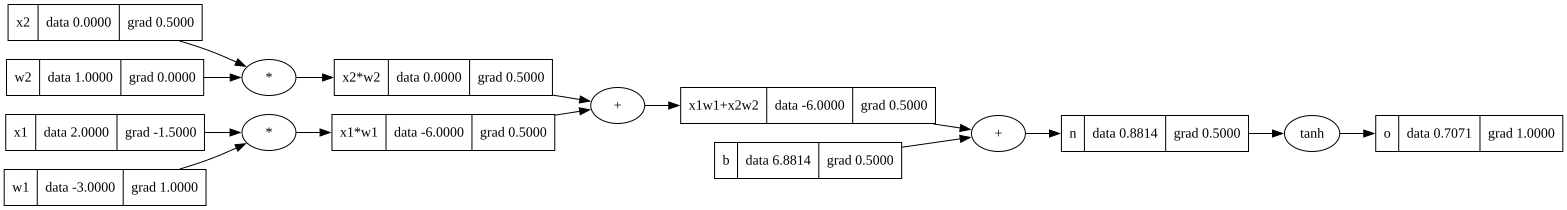

In [107]:
draw_dot(o)

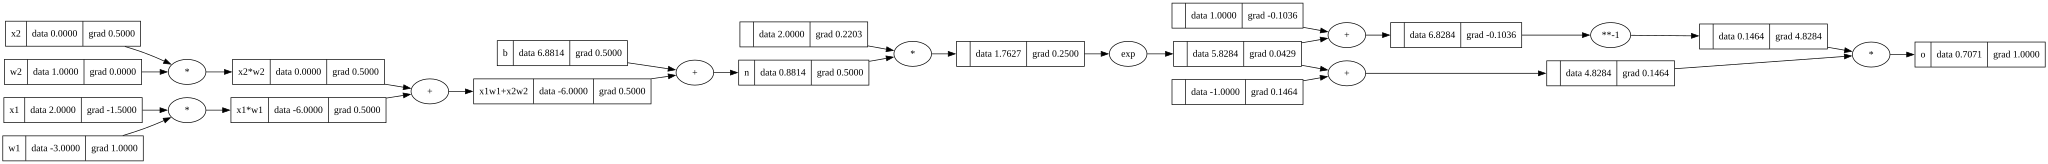

In [112]:
## express o interms of e
x1=Value(2,label="x1")
x2=Value(0,label="x2")

## weights w1, w2
w1=Value(-3,label="w1")
w2=Value(1,label="w2")

## bias of the neuron
b=Value(6.8813735870195432, label="b")

##x1*w1 + x2*w2 + b
x1w1=x1*w1; x1w1.label="x1*w1"
x2w2=x2*w2; x2w2.label="x2*w2"
x1w1x2w2=x1w1+x2w2; x1w1x2w2.label="x1w1+x2w2"
n=x1w1x2w2+b;n.label="n"
#--------------
e=(2*n).exp()
o=(e-1)/(e+1)
#-----------------
o.label="o"
o.backward()
draw_dot(o)

In [113]:
import torch

In [116]:
torch.Tensor([[1,2,3],[4,5,6]]).shape

torch.Size([2, 3])

In [118]:
torch.Tensor([2]).double().dtype

torch.float64

In [121]:
# example of 

x1=torch.Tensor([2]).double()                      ;x1.requires_grad=True
x2=torch.Tensor([0]).double()                      ;x2.requires_grad=True
w1=torch.Tensor([-3]).double()                      ;w1.requires_grad=True
w2=torch.Tensor([2]).double()                      ;w2.requires_grad=True
b=torch.Tensor([6.8813735870195432]).double()                      ;b.requires_grad=True
n=x1*w1+x2*w2+b
o=torch.tanh(n)

print(o.data.item())
o.backward()

print("---")
print("x2", x2.grad.item())
print("w2", w2.grad.item())
print("x1", x1.grad.item())
print("w1", w1.grad.item())

0.7071066904050358
---
x2 1.0000002567688737
w2 0.0
x1 -1.5000003851533106
w1 1.0000002567688737


In [127]:
o.data.item()

0.7071066904050358

In [128]:
o.item()

0.7071066904050358

In [148]:
class Neuron:
    
    def __init__(self,nin):
        self.w=[Value(np.random.uniform(-1,1)) for _ in range(nin)]
        self.b=Value(np.random.uniform(-1,1))

    def __call__(self,x):
        act=sum((wi*xi for wi,xi in zip(self.w,x)),self.b) 
        out=act.tanh()
        return out

class Layer:

    def __init__(self,nin,nout):             #nout - number of neurons in a single laeyer
        self.neurons=[Neuron(nin) for _ in range(nout)]

    def __call__(self,x):
        outs=[n(x) for n in self.neurons]
        return outs[0] if len(outs)==1 else outs

class MLP:
    def __init__(self,nin,nouts):    ## nin-number of inputs, ###nouts - list of nout's , nouts-define size of all layers
        sz=[nin]+nouts
        self.layers=[Layer(sz[i],sz[i+1]) for i in range(len(nouts))]
    def __call__(self,x):
        for layer in self.layers:
            x=layer(x)
        return x

    

x=[2,3,-1]
n=MLP(3,[4,4,1])
n(x)

Value(data=-0.31157447840812164)

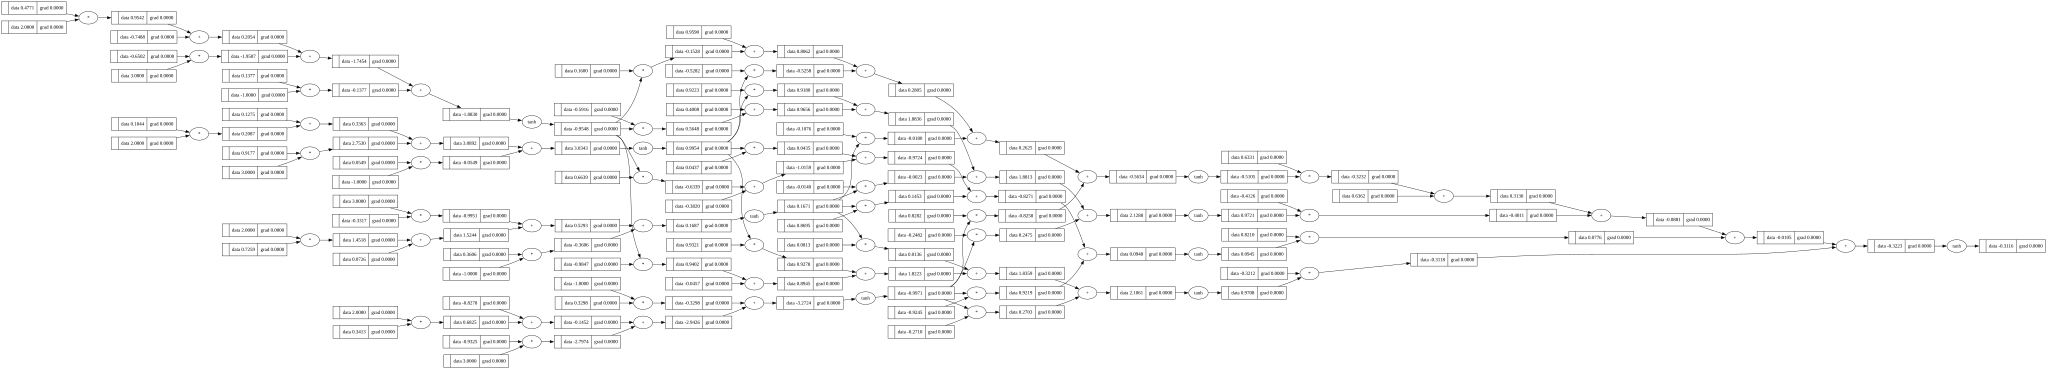

In [149]:
draw_dot(n(x))

In [169]:
xs = [
    [Value(2.0, label="x_0_0"), Value(3.0, label="x_0_1"), Value(-1.0, label="x_0_2")],
    [Value(3.0, label="x_1_0"), Value(-1.0, label="x_1_1"), Value(0.5, label="x_1_2")],
    [Value(0.5, label="x_2_0"), Value(1.0, label="x_2_1"), Value(1.0, label="x_2_2")],
    [Value(1.0, label="x_3_0"), Value(1.0, label="x_3_1"), Value(-1.0, label="x_3_2")]
]
ys=[1,-1,-1,1] # desired target
ypred=[n(x) for x in xs]
ypred

[Value(data=-0.31157447840812164),
 Value(data=0.9637536027789113),
 Value(data=-0.025689128813446926),
 Value(data=-0.20738514510061318)]

In [170]:
loss=sum([(yout-ygt)**2 for ygt, yout in zip(ys,ypred)] )  ### ygt -y ground truth, yout - y output )

loss

Value(data=7.98361638716062)

In [171]:
loss.backward()

In [172]:
n.layers[0].neurons[0].w[0].grad

-0.986339412406967

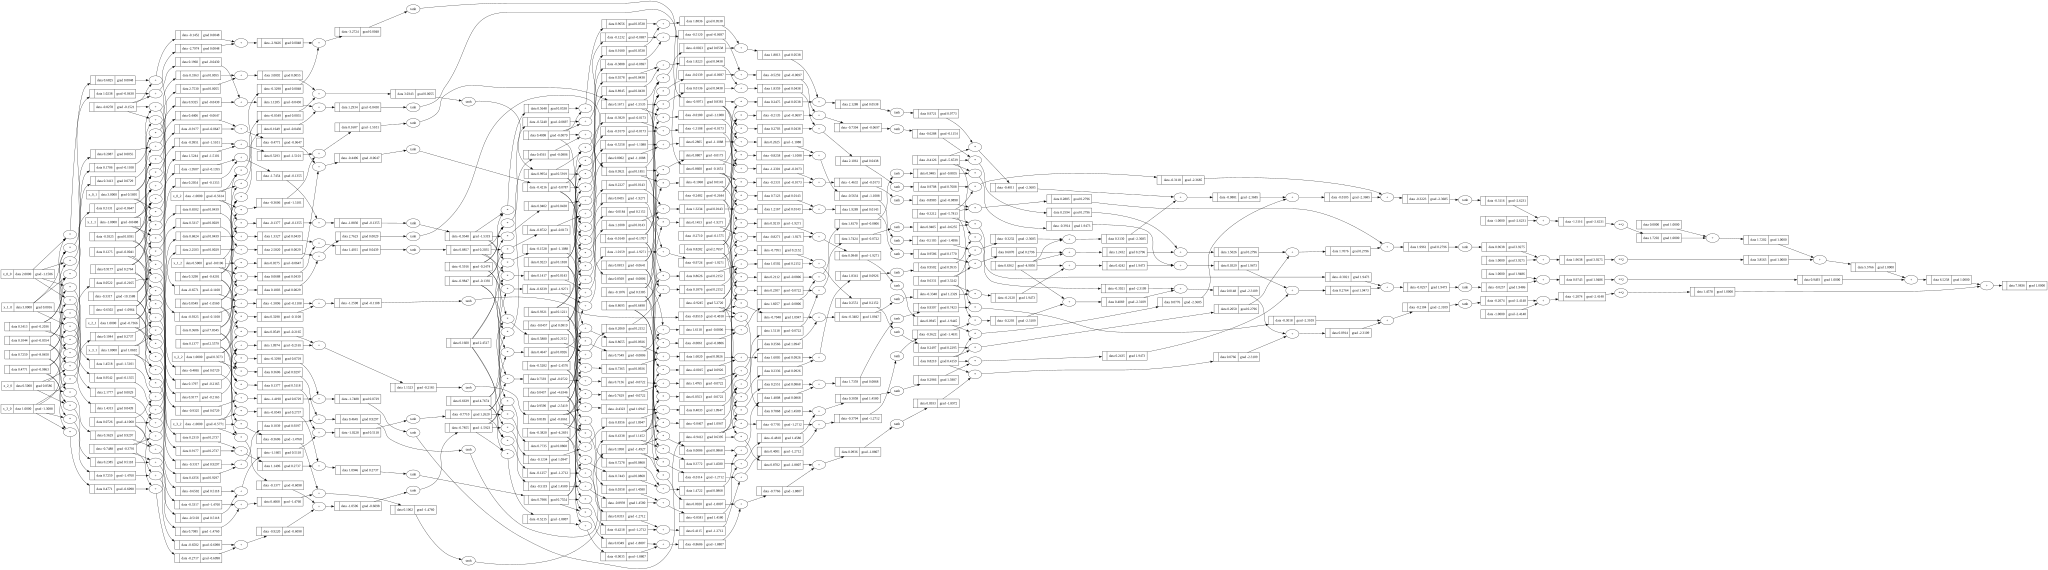

In [173]:
draw_dot(loss)

In [178]:
# added parameters to Neurons class

class Neuron:
    
    def __init__(self,nin):
        self.w=[Value(np.random.uniform(-1,1)) for _ in range(nin)]
        self.b=Value(np.random.uniform(-1,1))

    def __call__(self,x):
        act=sum((wi*xi for wi,xi in zip(self.w,x)),self.b) 
        out=act.tanh()
        return out
    def parameters(self):
        return self.w + [self.b]

class Layer:

    def __init__(self,nin,nout):             #nout - number of neurons in a single laeyer
        self.neurons=[Neuron(nin) for _ in range(nout)]

    def __call__(self,x):
        outs=[n(x) for n in self.neurons]
        return outs[0] if len(outs)==1 else outs
    def parameters(self):
        params=[]
        for neuron in self.neurons:
            params.extend(neuron.parameters())
        return params

class MLP:
    def __init__(self,nin,nouts):    ## nin-number of inputs, ###nouts - list of nout's , nouts-define size of all layers
        sz=[nin]+nouts
        self.layers=[Layer(sz[i],sz[i+1]) for i in range(len(nouts))]
    def __call__(self,x):
        for layer in self.layers:
            x=layer(x)
        return x
    def parameters (self):
        return [p for layer in self.layers for p in layer.parameters()]

In [177]:
## nested list comprehensions
a=[[1,2],[3,4], [5]]
[i for j in a for i in j]

[1, 2, 3, 4, 5]

In [179]:
x=[2,3,-1]
n=MLP(3,[4,4,1])
n(x)

Value(data=-0.8589081156204736)

In [182]:
len(n.parameters())

41

In [183]:
xs = [
    [Value(2.0, label="x_0_0"), Value(3.0, label="x_0_1"), Value(-1.0, label="x_0_2")],
    [Value(3.0, label="x_1_0"), Value(-1.0, label="x_1_1"), Value(0.5, label="x_1_2")],
    [Value(0.5, label="x_2_0"), Value(1.0, label="x_2_1"), Value(1.0, label="x_2_2")],
    [Value(1.0, label="x_3_0"), Value(1.0, label="x_3_1"), Value(-1.0, label="x_3_2")]
]
ys=[1,-1,-1,1] # desired target
ypred=[n(x) for x in xs]
ypred


[Value(data=-0.8589081156204736),
 Value(data=0.8001855463788079),
 Value(data=-0.8222380724222819),
 Value(data=-0.88765849599953)]

In [184]:
loss=sum([(yout-ygt)**2 for ygt, yout in zip(ys,ypred)] )  ### ygt -y ground truth, yout - y output )

loss

Value(data=10.291061284126181)

In [185]:
loss.backward()

In [244]:
xs = [
    [Value(2.0, label="x_0_0"), Value(3.0, label="x_0_1"), Value(-1.0, label="x_0_2")],
    [Value(3.0, label="x_1_0"), Value(-1.0, label="x_1_1"), Value(0.5, label="x_1_2")],
    [Value(0.5, label="x_2_0"), Value(1.0, label="x_2_1"), Value(1.0, label="x_2_2")],
    [Value(1.0, label="x_3_0"), Value(1.0, label="x_3_1"), Value(-1.0, label="x_3_2")]
]
ys=[1,-1,-1,1] # desired target
ypred=[n(x) for x in xs]
ypred

[Value(data=-0.9999999259452583),
 Value(data=-0.9999933332865151),
 Value(data=-0.9999999101011686),
 Value(data=-0.9999999450221082)]

In [252]:
x=[2,3,-1]
n=MLP(3,[4,4,1])
n(x)

Value(data=-0.8468400040399532)

In [324]:
n.layers[0].neurons[0].w[0].grad

-0.36516277156182275

In [325]:
n.layers[0].neurons[0].w[0].data

-0.31231839685518953

In [326]:
for p in n.parameters():
    p.data+=-0.1*p.grad
    

In [327]:
n.layers[0].neurons[0].w[0].data

-0.27580211969900725

In [328]:
ypred=[n(x) for x in xs]
loss=sum([(yout-ygt)**2 for ygt, yout in zip(ys,ypred)] )  ### ygt -y ground truth, yout - y output )

loss

Value(data=0.00013088303456470915)

In [329]:
loss.backward()

In [330]:
ypred

[Value(data=0.9886721720633337),
 Value(data=-0.9999087968710831),
 Value(data=-0.9999682916379714),
 Value(data=0.9984018681621829)]

In [331]:
n.parameters()

[Value(data=-0.27580211969900725),
 Value(data=0.2969220741690583),
 Value(data=-0.48570858030151437),
 Value(data=-0.2921972931745829),
 Value(data=-0.39721283294530874),
 Value(data=0.49777751643094104),
 Value(data=-3.27849089836912),
 Value(data=-1.3905671220679505),
 Value(data=0.5115366950826861),
 Value(data=-0.20004748082772886),
 Value(data=4.715439157860723),
 Value(data=2.2225851089526842),
 Value(data=-0.2912020253725444),
 Value(data=-1.0919668583537447),
 Value(data=-1.5679094291720443),
 Value(data=-0.7028203860236863),
 Value(data=0.04919706598000494),
 Value(data=0.85409653412113),
 Value(data=-5.246269267667006),
 Value(data=2.9317909675522285),
 Value(data=0.27207254508960693),
 Value(data=-0.08116364731529083),
 Value(data=-0.09691250579448966),
 Value(data=2.2509636790070293),
 Value(data=0.7020101426787111),
 Value(data=0.35491272022425563),
 Value(data=-0.9388409700159104),
 Value(data=1.7624173468308342),
 Value(data=-2.8189065170164045),
 Value(data=1.013262665

In [ ]:
### initalize network from scratch

In [340]:
x=[2,3,-1]
n=MLP(3,[4,4,1])
n(x)

Value(data=0.5643805686165894)

In [341]:
xs = [
    [Value(2.0, label="x_0_0"), Value(3.0, label="x_0_1"), Value(-1.0, label="x_0_2")],
    [Value(3.0, label="x_1_0"), Value(-1.0, label="x_1_1"), Value(0.5, label="x_1_2")],
    [Value(0.5, label="x_2_0"), Value(1.0, label="x_2_1"), Value(1.0, label="x_2_2")],
    [Value(1.0, label="x_3_0"), Value(1.0, label="x_3_1"), Value(-1.0, label="x_3_2")]
]
ys=[1,-1,-1,1] # desired target

In [350]:
## !!! cell 662 - 599
for k in range(80):
    ## forward pass
    ypred=[n(x) for x in xs]
    loss=sum((yout-ygt)**2 for ygt,yout in zip(ys,ypred))

    #backward pass
    for p in n.parameters():
        p.grad=0
    loss.backward()

    #update
    for p in n.parameters():
        p.data+=-0.05 * p.grad 

    print(k,loss.data)

    

0 0.008600029275253575
1 0.008485558382410118
2 0.008374051701724198
3 0.008265396273398697
4 0.00815948478367967
5 0.008056215217386248
6 0.007955490535737244
7 0.007857218377356107
8 0.00776131078053371
9 0.007667683925010289
10 0.007576257891696398
11 0.0074869564388982575
12 0.007399706793741648
13 0.007314439457605557
14 0.007231088024481483
15 0.00714958901126919
16 0.0070698816991047984
17 0.006991907984895107
18 0.0069156122423011165
19 0.006840941191478014
20 0.006767843776934887
21 0.006696271052931788
22 0.006626176075876768
23 0.006557513803230417
24 0.006490240998463734
25 0.006424316141651408
26 0.006359699345314789
27 0.006296352275159217
28 0.006234238075377227
29 0.006173321298213728
30 0.006113567837513163
31 0.006054944865988339
32 0.005997420775970415
33 0.005940965123417363
34 0.0058855485749734334
35 0.0058311428578883455
36 0.005777720712617288
37 0.005725255847936174
38 0.0056737228984183215
39 0.005623097384128477
40 0.005573355672401166
41 0.005524474941578501

In [351]:
ypred

[Value(data=0.9695836450845331),
 Value(data=-0.9717789973589995),
 Value(data=-0.964798153414456),
 Value(data=0.9656691281411056)]

In [ ]:
# From this step first lecture ends and futher is a little bit improvisation


In [8]:
# adding ReLU to value class 
class Value:
    def __init__(self, data,_children=(),_op="", label="" ):
        self.data = data
        self.grad=0.0
        self._backward= lambda : None
        self._prev=set(_children)
        self._op=_op
        self.label=label
    def __repr__(self):
        return f"Value(data={self.data})"
        
    def __add__(self,other):
        other=other if isinstance(other, Value)  else Value(other)
        out=Value(self.data + other.data,(self, other),"+")                
        def _backward():
            self.grad+=1.0*out.grad
            other.grad+=1.0*out.grad          
        out._backward=_backward
        return out
    def __radd__ (self,other):
        return self+other
        
    def __mul__(self,other):
        other=other if isinstance(other, Value)  else Value(other)
        out=Value(self.data * other.data,(self, other),"*")
        
        def _backward():
            self.grad+=other.data*out.grad
            other.grad+=self.data*out.grad
        out._backward=_backward
        
        return out

    def __pow__(self,other):
        assert isinstance (other,(int,float)), "only supporting int/float power for now"
        out=Value(self.data**other,(self,), f'**{other}')
        def _backward ():
            self.grad+=out.grad*other*self.data**(other-1)
        out._backward=_backward
        return out
        

    def __rmul__(self,other):
        return self*other

    def __truediv__(self,other):
        return self*other**-1

    def __neg__(self):
        return self*(-1)

    def __sub__(self,other):
        return self+(-other)
    
    def exp(self):
        x=self.data
        out=Value(math.exp(x),(self,),'exp')

        def backward():
            self.grad+=out.data*out.grad
        out._backward=backward
        return out
    def tanh(self):
        x=self.data
        t=(math.exp(2*x)-1)/(math.exp(2*x)+1)
        out=Value(t,(self,),"tanh")
        def _backward():
            self.grad+=(1-t**2)*out.grad
        out._backward=_backward
        return out

    def relu (self):
        out= Value(0 if self.data<0 else self.data, (self,),"ReLU")
        def _backward():
            self.grad+=(self.data>0)*out.grad
        out._backward=_backward
        return out

        
    def backward(self): ## added function backward to class
        topo = []
        visited = set()
        
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)
        
        build_topo(self)
        self.grad=1
        for node in reversed(topo):
            node._backward()
    
            

In [14]:
# change function from tanh to ReLU

class Neuron:
    
    def __init__(self,nin):
        self.w=[Value(np.random.uniform(-1,1)) for _ in range(nin)]
        self.b=Value(np.random.uniform(-1,1))

    def __call__(self,x):
        act=sum((wi*xi for wi,xi in zip(self.w,x)),self.b) 
        out=act.tanh()
        return out
    def parameters(self):
        return self.w + [self.b]

class Layer:

    def __init__(self,nin,nout):             #nout - number of neurons in a single laeyer
        self.neurons=[Neuron(nin) for _ in range(nout)]

    def __call__(self,x):
        outs=[n(x) for n in self.neurons]
        return outs[0] if len(outs)==1 else outs
    def parameters(self):
        params=[]
        for neuron in self.neurons:
            params.extend(neuron.parameters())
        return params

class MLP:
    def __init__(self,nin,nouts):    ## nin-number of inputs, ###nouts - list of nout's , nouts-define size of all layers
        sz=[nin]+nouts
        self.layers=[Layer(sz[i],sz[i+1]) for i in range(len(nouts))]
    def __call__(self,x):
        for layer in self.layers:
            x=layer(x)
        return x
    def parameters (self):
        return [p for layer in self.layers for p in layer.parameters()]

In [15]:
x=[2,3,-1]
n=MLP(3,[4,4,1])
n(x)

Value(data=0.8044476273192397)

In [16]:
xs = [
    [Value(2.0, label="x_0_0"), Value(3.0, label="x_0_1"), Value(-1.0, label="x_0_2")],
    [Value(3.0, label="x_1_0"), Value(-1.0, label="x_1_1"), Value(0.5, label="x_1_2")],
    [Value(0.5, label="x_2_0"), Value(1.0, label="x_2_1"), Value(1.0, label="x_2_2")],
    [Value(1.0, label="x_3_0"), Value(1.0, label="x_3_1"), Value(-1.0, label="x_3_2")]
]
ys=[1,-1,-1,1] # desired target

In [17]:
for k in range(80):
    ## forward pass
    ypred=[n(x) for x in xs]
    loss=sum((yout-ygt)**2 for ygt,yout in zip(ys,ypred))

    #backward pass
    for p in n.parameters():
        p.grad=0
    loss.backward()

    #update
    for p in n.parameters():
        p.data+=-0.05 * p.grad 

    print(k,loss.data)


0 2.1284853961679566
1 0.6133057877772152
2 0.35050158915968915
3 0.27280324048141685
4 0.22132696343031216
5 0.18482592601378683
6 0.15776659743345167
7 0.13701674262969032
8 0.12067113341128974
9 0.10750851640500234
10 0.09671285309628688
11 0.0877199213500787
12 0.08012824395441571
13 0.07364504999540364
14 0.06805225893404133
15 0.06318438132970057
16 0.058913762083446876
17 0.05514048627335364
18 0.05178532531885392
19 0.04878471283082875
20 0.04608710425737312
21 0.043650298004443394
22 0.041439436148009226
23 0.03942549304626493
24 0.03758411925886381
25 0.03589474762032095
26 0.03433989508106749
27 0.03290461237726815
28 0.03157604648719675
29 0.030343089967678788
30 0.02919609781541441
31 0.02812665724988552
32 0.0271273992981721
33 0.026191843641437222
34 0.025314270110710604
35 0.0244896116732035
36 0.023713364855503374
37 0.022981514396750755
38 0.02229046957849286
39 0.021637010185940664
40 0.02101824045285804
41 0.02043154965529336
42 0.019874578267270113
43 0.01934518878

In [18]:
ypred

[Value(data=0.9658631712565304),
 Value(data=-0.9687946595076384),
 Value(data=-0.9386872029331861),
 Value(data=0.9390034216373815)]

In [41]:
## classes for tanh activation function
class Neuron:
    def __init__ (self,nin):                  ##nin number of input
        self.w=[Value(np.random.uniform(-1,1)) for _ in range(nin)]
        self.b=Value(np.random.uniform(-1,1))
    def __call__(self,x):
        act=sum((wi*xi for wi,xi in zip (self.w,x)), self.b)
        out=act.tanh()
        return out
    def parameters(self):
        return self.w + [self.b]

class Layer:
    def __init__(self,nin,nout):
        self.Neurons= [Neuron(nin) for _ in range(nout)]

    def __call__(self,x):
        outs= [n(x) for n in self.Neurons]
        return outs[0] if len(outs)==1 else outs
    def parameters (self):
        a=[]
        for n in self.Neurons:
            a.extend(n.parameters())
        return a
class MLP:
    def __init__ (self,nin,nouts):
        sz=[nin]+nouts
        self.Layers=[Layer(sz[i],sz[i+1]) for i in range(len(sz)-1)]
    def __call__(self,x):
        for l in self.Layers:
            x=l(x)
        return x
    def parameters(self):
        return [p for l in self.Layers for p in l.parameters()]
    

        

In [42]:
x=[2,3,-1]
n=MLP(3,[4,4,1])
n(x)
xs = [
    [Value(2.0, label="x_0_0"), Value(3.0, label="x_0_1"), Value(-1.0, label="x_0_2")],
    [Value(3.0, label="x_1_0"), Value(-1.0, label="x_1_1"), Value(0.5, label="x_1_2")],
    [Value(0.5, label="x_2_0"), Value(1.0, label="x_2_1"), Value(1.0, label="x_2_2")],
    [Value(1.0, label="x_3_0"), Value(1.0, label="x_3_1"), Value(-1.0, label="x_3_2")]
]
ys=[1,-1,-1,1] # desired target

In [50]:
for k in range(80):
    ## forward pass
    ypred=[n(x) for x in xs]
    loss=sum((yout-ygt)**2 for ygt,yout in zip(ys,ypred))

    #backward pass
    for p in n.parameters():
        p.grad=0
    loss.backward()

    #update
    for p in n.parameters():
        p.data+=-0.05 * p.grad 

    print(k,loss.data)

0 0.0014859934145720754
1 0.0014811015712870531
2 0.001476241122186802
3 0.001471411768956167
4 0.00146661321702612
5 0.0014618451755154358
6 0.0014571073571733417
7 0.001452399478323238
8 0.0014477212588075814
9 0.0014430724219335576
10 0.001438452694420039
11 0.001433861806345233
12 0.001429299491095483
13 0.0014247654853149548
14 0.001420259528856109
15 0.0014157813647312808
16 0.0014113307390650129
17 0.0014069074010472245
18 0.001402511102887262
19 0.0013981415997687979
20 0.001393798649805503
21 0.0013894820139974515
22 0.0013851914561884406
23 0.0013809267430239204
24 0.0013766876439096846
25 0.0013724739309714721
26 0.00136828537901497
27 0.0013641217654867782
28 0.00135998287043592
29 0.0013558684764760408
30 0.001351778368748309
31 0.0013477123348849018
32 0.0013436701649731145
33 0.0013396516515202172
34 0.0013356565894186787
35 0.0013316847759122113
36 0.0013277360105622403
37 0.0013238100952150745
38 0.0013199068339694825
39 0.0013160260331449263
40 0.0013121675012503302
4

In [51]:
ypred

[Value(data=0.98479022301816),
 Value(data=-0.9834678476880471),
 Value(data=-0.981002182959001),
 Value(data=0.9823459601965696)]

In [58]:
## build for ReLU activation function, add value to detec last layyer
class Neuron:
    def __init__ (self,nin, last_layer=False):                  ##nin number of input
        self.w=[Value(np.random.uniform(-1,1)) for _ in range(nin)]
        self.b=Value(np.random.uniform(-1,1))
        self.last_layer=last_layer
    def __call__(self,x):
        act=sum((wi*xi for wi,xi in zip (self.w,x)), self.b)
        out=act.relu()
        return out if self.last_layer==False else act
    def parameters(self):
        return self.w + [self.b]

class Layer:
    def __init__(self,nin,nout,last_layer=False):
        self.Neurons= [Neuron(nin,last_layer) for _ in range(nout)]

    def __call__(self,x):
        outs= [n(x) for n in self.Neurons]
        return outs[0] if len(outs)==1 else outs
    def parameters (self):
        a=[]
        for n in self.Neurons:
            a.extend(n.parameters())
        return a
class MLP:
    def __init__ (self,nin,nouts):
        sz=[nin]+nouts
        self.Layers=[Layer(sz[i],sz[i+1]) for i in range(len(sz)-2)]+[Layer(sz[len(sz)-2],sz[len(sz)-1],last_layer=True)]
    def __call__(self,x):
        for l in self.Layers:
            x=l(x)
        return x
    def parameters(self):
        return [p for l in self.Layers for p in l.parameters()]
    

        

In [59]:
## chech ReLU
x=[2,3,-1]
n=MLP(3,[4,4,1])
n(x)
xs = [
    [Value(2.0, label="x_0_0"), Value(3.0, label="x_0_1"), Value(-1.0, label="x_0_2")],
    [Value(3.0, label="x_1_0"), Value(-1.0, label="x_1_1"), Value(0.5, label="x_1_2")],
    [Value(0.5, label="x_2_0"), Value(1.0, label="x_2_1"), Value(1.0, label="x_2_2")],
    [Value(1.0, label="x_3_0"), Value(1.0, label="x_3_1"), Value(-1.0, label="x_3_2")]
]
ys=[1,-1,-1,1] # desired target

In [60]:
for k in range(80):
    ## forward pass
    ypred=[n(x) for x in xs]
    loss=sum((yout-ygt)**2 for ygt,yout in zip(ys,ypred))

    #backward pass
    for p in n.parameters():
        p.grad=0
    loss.backward()

    #update
    for p in n.parameters():
        p.data+=-0.05 * p.grad 

    print(k,loss.data)

0 17.352925856707454
1 12.190288925264785
2 4.352058520563677
3 2.3563991550388566
4 1.7573987835198879
5 1.3774117556746992
6 0.9797100579924316
7 0.7199778318044191
8 0.5145519433015165
9 0.35668100738777053
10 0.24059935377360628
11 0.17129390277349638
12 0.12481966998365061
13 0.09102068486949065
14 0.06619927104348723
15 0.04803876345454585
16 0.03523889180125033
17 0.025811270546129923
18 0.01859566058746351
19 0.013418001453065908
20 0.009673150771285558
21 0.006968121559224199
22 0.00501630997954328
23 0.0036092611618905616
24 0.00259570104152515
25 0.0018660554801587434
26 0.001341078006680186
27 0.0009635295965891576
28 0.0006921114772547008
29 0.0004970528247936195
30 0.0003569091110667951
31 0.000256243204903423
32 0.0001839484081959544
33 0.00013203726922214132
34 9.476773600133751e-05
35 6.801325635898049e-05
36 4.880906341788153e-05
37 3.5025572290641015e-05
38 2.513340125972664e-05
39 1.8034388629961593e-05
40 1.2940115456746128e-05
41 9.284606569325549e-06
42 6.6616104

In [61]:
ypred

[Value(data=0.9999991038383579),
 Value(data=-0.9999961862104885),
 Value(data=-0.9999961862104885),
 Value(data=0.9999991038383579)]

In [ ]:
### Now let try leaky ReLU

In [3]:
# adding Leaky ReLU to value class 
class Value:
    def __init__(self, data,_children=(),_op="", label="" ):
        self.data = data
        self.grad=0.0
        self._backward= lambda : None
        self._prev=set(_children)
        self._op=_op
        self.label=label
    def __repr__(self):
        return f"Value(data={self.data})"
        
    def __add__(self,other):
        other=other if isinstance(other, Value)  else Value(other)
        out=Value(self.data + other.data,(self, other),"+")                
        def _backward():
            self.grad+=1.0*out.grad
            other.grad+=1.0*out.grad          
        out._backward=_backward
        return out
    def __radd__ (self,other):
        return self+other
        
    def __mul__(self,other):
        other=other if isinstance(other, Value)  else Value(other)
        out=Value(self.data * other.data,(self, other),"*")
        
        def _backward():
            self.grad+=other.data*out.grad
            other.grad+=self.data*out.grad
        out._backward=_backward
        
        return out

    def __pow__(self,other):
        assert isinstance (other,(int,float)), "only supporting int/float power for now"
        out=Value(self.data**other,(self,), f'**{other}')
        def _backward ():
            self.grad+=out.grad*other*self.data**(other-1)
        out._backward=_backward
        return out
        

    def __rmul__(self,other):
        return self*other

    def __truediv__(self,other):
        return self*other**-1

    def __neg__(self):
        return self*(-1)

    def __sub__(self,other):
        return self+(-other)
    
    def exp(self):
        x=self.data
        out=Value(math.exp(x),(self,),'exp')

        def backward():
            self.grad+=out.data*out.grad
        out._backward=backward
        return out
    def tanh(self):
        x=self.data
        t=(math.exp(2*x)-1)/(math.exp(2*x)+1)
        out=Value(t,(self,),"tanh")
        def _backward():
            self.grad+=(1-t**2)*out.grad
        out._backward=_backward
        return out

    def relu (self):
        out= Value(0 if self.data<0 else self.data, (self,),"ReLU")
        def _backward():
            self.grad+=(self.data>0)*out.grad
        out._backward=_backward
        return out
        
    def l_relu(self,alpha=0.05):    ### leaky ReLU
        out=Value(alpha * self.data if self.data<0 else self.data, (self,),"Leaky_ReLU")
        def _backward():
            self.grad+=out.grad if out.data >0 else alpha*out.grad
        out._backward=_backward
        return out
        
    def backward(self): ## added function backward to class
        topo = []
        visited = set()
        
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)
        
        build_topo(self)
        self.grad=1
        for node in reversed(topo):
            node._backward()
    
            

In [4]:
## build for Leaky ReLU activation function
class Neuron:
    def __init__ (self,nin, last_layer=False):                  ##nin number of input
        self.w=[Value(np.random.uniform(-1,1)) for _ in range(nin)]
        self.b=Value(np.random.uniform(-1,1))
        self.last_layer=last_layer
    def __call__(self,x):
        act=sum((wi*xi for wi,xi in zip (self.w,x)), self.b)
        out=act.l_relu()
        return out if self.last_layer==False else act
    def parameters(self):
        return self.w + [self.b]

class Layer:
    def __init__(self,nin,nout,last_layer=False):
        self.Neurons= [Neuron(nin,last_layer) for _ in range(nout)]

    def __call__(self,x):
        outs= [n(x) for n in self.Neurons]
        return outs[0] if len(outs)==1 else outs
    def parameters (self):
        a=[]
        for n in self.Neurons:
            a.extend(n.parameters())
        return a
class MLP:
    def __init__ (self,nin,nouts):
        sz=[nin]+nouts
        self.Layers=[Layer(sz[i],sz[i+1]) for i in range(len(sz)-2)]+[Layer(sz[len(sz)-2],sz[len(sz)-1],last_layer=True)]
    def __call__(self,x):
        for l in self.Layers:
            x=l(x)
        return x
    def parameters(self):
        return [p for l in self.Layers for p in l.parameters()]
    

        

In [6]:
## chech ReLU
x=[2,3,-1]
n=MLP(3,[4,4,1])
n(x)
xs = [
    [Value(2.0, label="x_0_0"), Value(3.0, label="x_0_1"), Value(-1.0, label="x_0_2")],
    [Value(3.0, label="x_1_0"), Value(-1.0, label="x_1_1"), Value(0.5, label="x_1_2")],
    [Value(0.5, label="x_2_0"), Value(1.0, label="x_2_1"), Value(1.0, label="x_2_2")],
    [Value(1.0, label="x_3_0"), Value(1.0, label="x_3_1"), Value(-1.0, label="x_3_2")]
]
ys=[1,-1,-1,1] # desired target

In [9]:
for k in range(80):
    ## forward pass
    ypred=[n(x) for x in xs]
    loss=sum((yout-ygt)**2 for ygt,yout in zip(ys,ypred))

    #backward pass
    for p in n.parameters():
        p.grad=0
    loss.backward()

    #update
    for p in n.parameters():
        p.data+=-0.05 * p.grad 

    print(k,loss.data)
ypred

0 0.14930040463308497
1 0.14313053844062318
2 0.13731480693817727
3 0.131826522387342
4 0.12664156074512217
5 0.12173804421570406
6 0.11709607605806982
7 0.11269751620336318
8 0.10852578937383599
9 0.10456571954543113
10 0.10080338609171954
11 0.09598208489542434
12 0.09770129690256367
13 0.0989448380471096
14 0.0906467894693338
15 0.08706854446070525
16 0.0839884982200953
17 0.07955120111192915
18 0.08129798219498804
19 0.08319762063394492
20 0.07615103545559851
21 0.07317705835406631
22 0.07051569556747639
23 0.07897095092607402
24 0.07938700909735893
25 0.06796096712125975
26 0.06491850873165289
27 0.06258084916313371
28 0.06045238838493257
29 0.05846683138830647
30 0.056596986776666955
31 0.05482516468262719
32 0.05236955031493297
33 0.05246110953320778
34 0.05303518169265166
35 0.049772589340827615
36 0.04811512063260072
37 0.04613111009784862
38 0.047462787813040336
39 0.04789048936543764
40 0.04408089885902507
41 0.04254963139268276
42 0.041230876438672986
43 0.03999748675613624

[Value(data=1.0880116072039534),
 Value(data=-0.9882552817731445),
 Value(data=-0.9917099687178285),
 Value(data=0.9069073109086723)]